In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.ensemble import RandomForestRegressor

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

import warnings
warnings.filterwarnings('ignore')

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving SPAS-Dataset-BD.csv to SPAS-Dataset-BD.csv


In [ ]:
df = pd.read_csv("SPAS-Dataset-BD.csv")

df.head()

,Area,AP Ratio,District,Season,Avg Temp,Avg Humidity,Crop Name,Transplant,Growth,Harvest,Production,Max Temp,Min Temp,Max Relative Humidity,Min Relative Humidity
0,177321,0.8510272331,Bagerhat,Kharif 2,26.0,72.5,Aman,June,July to Oct,Nov to Dec,150905,40,12.0,60,85
1,25646,1.175777899,Bandarban,Kharif 2,26.0,72.5,Aman,June,July to Oct,Nov to Dec,30154,40,12.0,60,85
2,231401,0.7705887183,Barguna,Kharif 2,26.0,72.5,Aman,June,July to Oct,Nov to Dec,178315,40,12.0,60,85
3,302665,0.7571043893,Barishal,Kharif 2,26.0,72.5,Aman,June,July to Oct,Nov to Dec,229149,40,12.0,60,85
4,388575,1.100652384,Bhola,Kharif 2,26.0,72.5,Aman,June,July to Oct,Nov to Dec,427686,40,12.0,60,85


In [ ]:
df.shape

(4608, 15)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4608 entries, 0 to 4607
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Area                   4608 non-null   int64  
 1   AP Ratio               4608 non-null   object 
 2   District               4608 non-null   object 
 3   Season                 4607 non-null   object 
 4   Avg Temp               4608 non-null   float64
 5   Avg Humidity           4608 non-null   float64
 6   Crop Name              4608 non-null   object 
 7   Transplant             4608 non-null   object 
 8   Growth                 4608 non-null   object 
 9   Harvest                4608 non-null   object 
 10  Production             4608 non-null   int64  
 11  Max Temp               4608 non-null   int64  
 12  Min Temp               4608 non-null   float64
 13  Max Relative Humidity  4608 non-null   int64  
 14  Min Relative Humidity  4608 non-null   int64  
dtypes: f

In [ ]:
df.isnull().sum()

,0
Area,0
AP Ratio,0
District,0
Season,1
Avg Temp,0
Avg Humidity,0
Crop Name,0
Transplant,0
Growth,0
Harvest,0


In [ ]:
df = df.drop(columns=['AP Ratio'])

In [ ]:
target = "Production"

In [ ]:
X = df.drop(columns=[target])

y = df[target]

In [ ]:
area_features = [
    "Area"
]

In [ ]:
climate_features = [
    "Avg Temp",
    "Avg Humidity",
    "Max Temp",
    "Min Temp",
    "Max Relative Humidity",
    "Min Relative Humidity"
]

In [ ]:
crop_features = [
    "Crop Name"
]

In [ ]:
district_features = [
    "District"
]

In [ ]:
lifecycle_features = [
    "Season",
    "Transplant",
    "Growth",
    "Harvest"
]

In [ ]:
experiments = {

"Area Only":
area_features,


"Climate Only":
climate_features,


"Crop Lifecycle":
crop_features + lifecycle_features,


"Without Area":
climate_features + crop_features + district_features + lifecycle_features,


"Full Features":
area_features + climate_features + crop_features + district_features + lifecycle_features

}

In [ ]:
def prepare_data(features):

    X = df[features]
    y = df["Production"]

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42
    )


    categorical = X.select_dtypes(
        include=['object']
    ).columns.tolist()


    numerical = X.select_dtypes(
        exclude=['object']
    ).columns.tolist()


    preprocessor = ColumnTransformer(
        transformers=[
            (
                "cat",
                OneHotEncoder(
                    handle_unknown="ignore"
                ),
                categorical
            ),

            (
                "num",
                "passthrough",
                numerical
            )
        ]
    )


    return X_train,X_test,y_train,y_test,preprocessor

In [ ]:
models = {

"Random Forest":
RandomForestRegressor(
    n_estimators=200,
    random_state=42
),


"XGBoost":
XGBRegressor(
    n_estimators=200,
    random_state=42
),


"LightGBM":
LGBMRegressor(
    n_estimators=200,
    random_state=42
)

}

In [ ]:
results=[]


for exp_name, features in experiments.items():

    print("\nRunning:", exp_name)


    X_train,X_test,y_train,y_test,preprocessor = prepare_data(features)


    for model_name, model in models.items():


        pipeline = Pipeline(
            steps=[
                ("preprocessor",preprocessor),
                ("model",model)
            ]
        )


        pipeline.fit(
            X_train,
            y_train
        )


        prediction = pipeline.predict(
            X_test
        )


        mae = mean_absolute_error(
            y_test,
            prediction
        )


        rmse = np.sqrt(
            mean_squared_error(
                y_test,
                prediction
            )
        )


        r2 = r2_score(
            y_test,
            prediction
        )


        results.append([
            exp_name,
            model_name,
            mae,
            rmse,
            r2
        ])


Running: Area Only
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000193 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 255
[LightGBM] [Info] Number of data points in the train set: 3686, number of used features: 1
[LightGBM] [Info] Start training from score 14367.046934

Running: Climate Only
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000264 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 111
[LightGBM] [Info] Number of data points in the train set: 3686, number of used features: 6
[LightGBM] [Info] Start training from score 14367.046934

Running: Crop Lifecycle
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000264 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] To

In [ ]:
results_df = pd.DataFrame(
    results,
    columns=[
        "Experiment",
        "Model",
        "MAE",
        "RMSE",
        "R2"
    ]
)


results_df

,Experiment,Model,MAE,RMSE,R2
0,Area Only,Random Forest,9388.788619,36888.785156,0.691184
1,Area Only,XGBoost,7581.419922,28315.202984,0.818051
2,Area Only,LightGBM,7887.042268,30631.924374,0.787059
3,Climate Only,Random Forest,15868.093058,54400.031176,0.328402
4,Climate Only,XGBoost,15919.444336,54436.032772,0.327513
5,Climate Only,LightGBM,15919.444185,54436.031746,0.327513
6,Crop Lifecycle,Random Forest,14123.954901,49521.037494,0.443467
7,Crop Lifecycle,XGBoost,14171.680664,49578.299769,0.442180
8,Crop Lifecycle,LightGBM,14168.751252,49578.135427,0.442183
9,Without Area,Random Forest,11510.862185,51496.861617,0.398172


In [ ]:
results_df.sort_values(
    by="R2",
    ascending=False
)

,Experiment,Model,MAE,RMSE,R2
12,Full Features,Random Forest,3258.672511,14087.495912,0.954962
13,Full Features,XGBoost,3510.888184,15688.216215,0.944146
14,Full Features,LightGBM,4450.938023,17187.073012,0.932963
1,Area Only,XGBoost,7581.419922,28315.202984,0.818051
2,Area Only,LightGBM,7887.042268,30631.924374,0.787059
0,Area Only,Random Forest,9388.788619,36888.785156,0.691184
11,Without Area,LightGBM,15012.429083,48623.675280,0.463454
6,Crop Lifecycle,Random Forest,14123.954901,49521.037494,0.443467
8,Crop Lifecycle,LightGBM,14168.751252,49578.135427,0.442183
7,Crop Lifecycle,XGBoost,14171.680664,49578.299769,0.442180


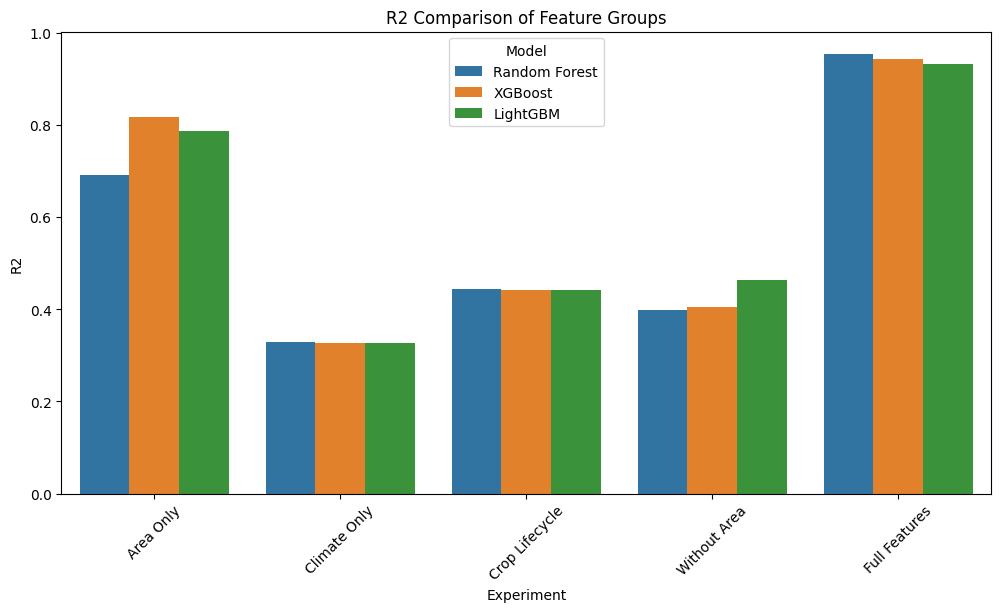

In [ ]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=results_df,
    x="Experiment",
    y="R2",
    hue="Model"
)

plt.xticks(rotation=45)

plt.title(
    "R2 Comparison of Feature Groups"
)

plt.show()

In [ ]:
model = LGBMRegressor()


In [ ]:
from sklearn.inspection import permutation_importance


result = permutation_importance(
    pipeline,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42
)

In [ ]:
full_features = (
    area_features
    + climate_features
    + crop_features
    + district_features
    + lifecycle_features
)

X = df[full_features]
y = df["Production"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
categorical = X.select_dtypes(include=['object']).columns.tolist()

numerical = X.select_dtypes(exclude=['object']).columns.tolist()


preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical
        ),
        (
            "num",
            "passthrough",
            numerical
        )
    ]
)

In [ ]:
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)


rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", rf_model)
    ]
)


rf_pipeline.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Crop Name', 'District',
                                                   'Season', 'Transplant',
                                                   'Growth', 'Harvest']),
                                                 ('num', 'passthrough',
                                                  ['Area', 'Avg Temp',
                                                   'Avg Humidity', 'Max Temp',
                                                   'Min Temp',
                                                   'Max Relative Humidity',
                                                   'Min Relative Humidity'])])),
                ('model',
                 RandomForestRegressor(n_estimators=200, random_state=42))])

In [ ]:
feature_names = (
    rf_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)


importance = (
    rf_pipeline
    .named_steps["model"]
    .feature_importances_
)


importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})


importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)


importance_df.head(20)

,Feature,Importance
226,num__Area,0.857849
232,num__Min Relative Humidity,0.017573
231,num__Max Relative Humidity,0.014093
196,cat__Harvest_Aug to Sep,0.012399
182,cat__Growth_Nov to Aug,0.011875
67,cat__Crop Name_Sugarcane,0.009843
227,num__Avg Temp,0.008275
138,cat__Season_Kharif 2,0.003725
112,cat__District_Mymensingh,0.003623
46,cat__Crop Name_Maize 2,0.003470


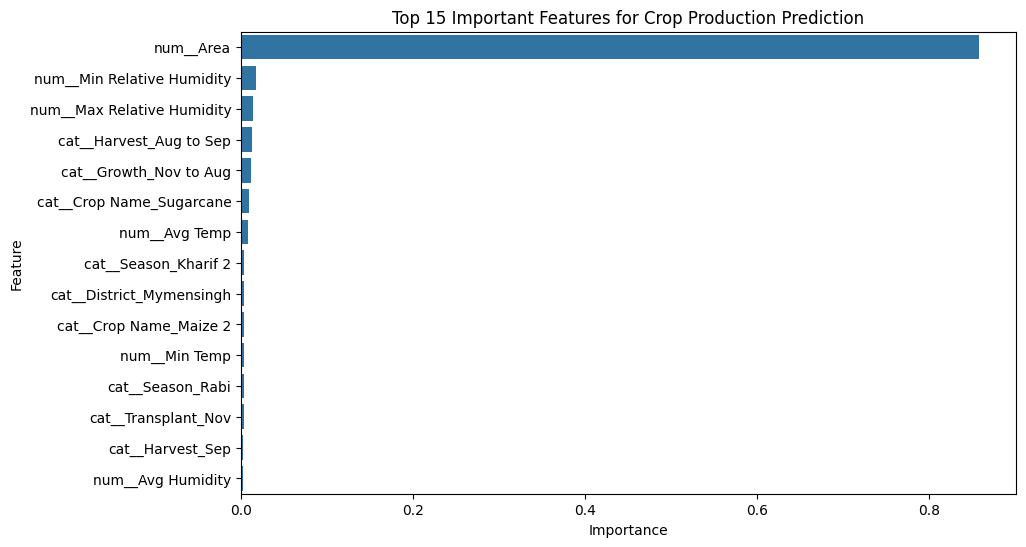

In [ ]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title(
    "Top 15 Important Features for Crop Production Prediction"
)

plt.show()

In [ ]:
importance_no_area = importance_df[
    importance_df["Feature"] != "num__Area"
]


importance_no_area.head(15)

,Feature,Importance
232,num__Min Relative Humidity,0.017573
231,num__Max Relative Humidity,0.014093
196,cat__Harvest_Aug to Sep,0.012399
182,cat__Growth_Nov to Aug,0.011875
67,cat__Crop Name_Sugarcane,0.009843
227,num__Avg Temp,0.008275
138,cat__Season_Kharif 2,0.003725
112,cat__District_Mymensingh,0.003623
46,cat__Crop Name_Maize 2,0.003470
230,num__Min Temp,0.003281


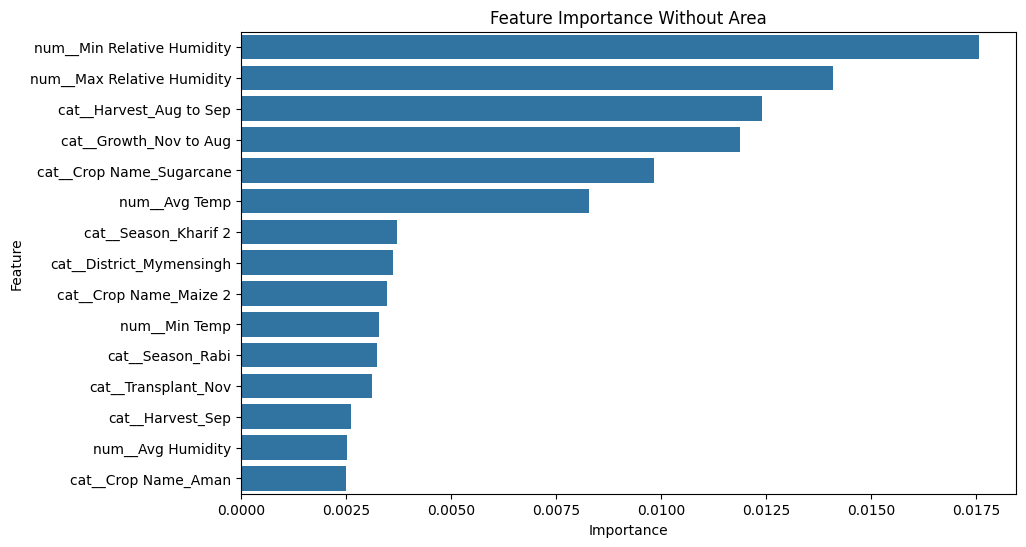

In [ ]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=importance_no_area.head(15),
    x="Importance",
    y="Feature"
)

plt.title(
    "Feature Importance Without Area"
)

plt.show()

In [ ]:
!pip install shap

In [ ]:
import shap

In [ ]:

X_test_transformed = (
    rf_pipeline
    .named_steps["preprocessor"]
    .transform(X_test)
)


if hasattr(X_test_transformed, "toarray"):
    X_test_transformed = X_test_transformed.toarray()


X_test_transformed = X_test_transformed.astype(float)

X_test_transformed.shape

(922, 233)

In [ ]:
import shap

explainer = shap.TreeExplainer(
    rf_pipeline.named_steps["model"]
)

shap_values = explainer.shap_values(
    X_test_transformed,
    check_additivity=False
)

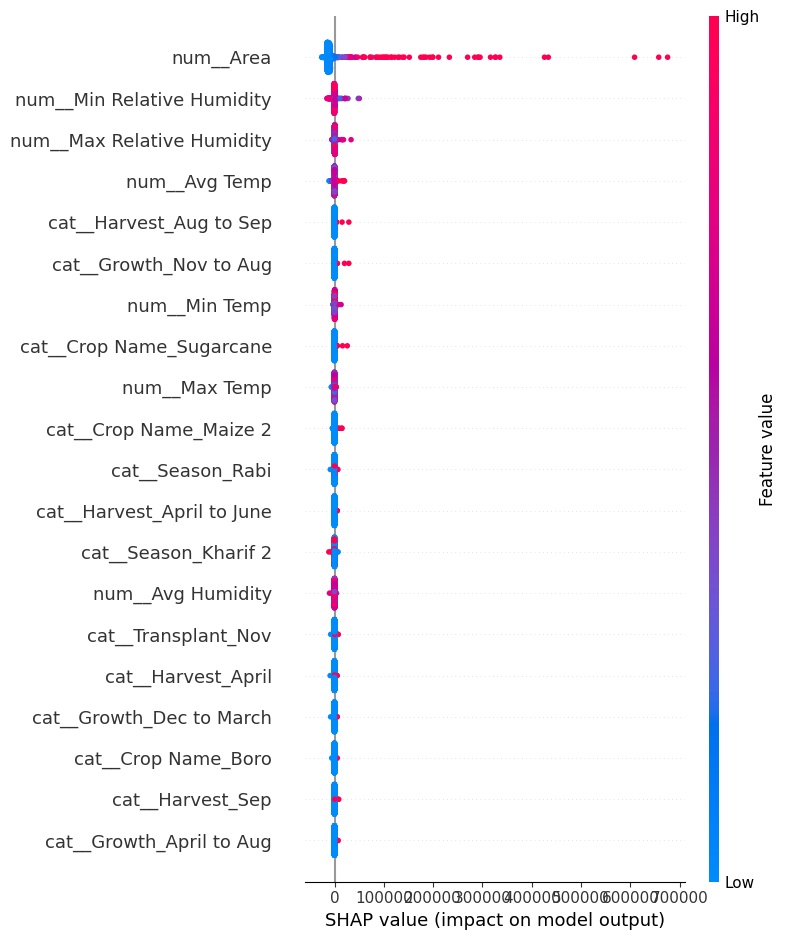

In [ ]:
feature_names = (
    rf_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)


shap.summary_plot(
    shap_values,
    X_test_transformed,
    feature_names=feature_names
)

In [2]:
import pandas as pd
import numpy as np
from google.colab import files

uploaded = files.upload()

filename = list(uploaded.keys())[0]
print("Loaded file:", filename)

df = pd.read_csv(filename)

print("\nShape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nExact duplicate rows:", df.duplicated().sum())

print("\nUnique Crop Names:", df["Crop Name"].nunique())
print("Unique Districts:", df["District"].nunique())

print("\nREF! rows:")
print(df[df["Crop Name"].astype(str).str.strip() == "REF!"])

if {"Production", "Area", "AP Ratio"}.issubset(df.columns):
    stored = pd.to_numeric(df["AP Ratio"], errors="coerce")
    calculated = df["Production"] / df["Area"]

    print(
        "\nAP Ratio = Production / Area:",
        np.allclose(
            stored,
            calculated,
            equal_nan=True,
            rtol=1e-5,
            atol=1e-5
        )
    )

Saving SPAS-Dataset-BD.csv to SPAS-Dataset-BD.csv
Loaded file: SPAS-Dataset-BD.csv

Shape: (4608, 15)

Columns:
['Area', 'AP Ratio', 'District', 'Season', 'Avg Temp', 'Avg Humidity', 'Crop Name', 'Transplant', 'Growth', 'Harvest', 'Production', 'Max Temp', 'Min Temp', 'Max Relative Humidity', 'Min Relative Humidity']

Missing values:
Area                     0
AP Ratio                 0
District                 0
Season                   1
Avg Temp                 0
Avg Humidity             0
Crop Name                0
Transplant               0
Growth                   0
Harvest                  0
Production               0
Max Temp                 0
Min Temp                 0
Max Relative Humidity    0
Min Relative Humidity    0
dtype: int64

Exact duplicate rows: 0

Unique Crop Names: 73
Unique Districts: 64

REF! rows:
Empty DataFrame
Columns: [Area, AP Ratio, District, Season, Avg Temp, Avg Humidity, Crop Name, Transplant, Growth, Harvest, Production, Max Temp, Min Temp, Max Relat

In [3]:
import pandas as pd
import numpy as np

# numeric conversion
area = pd.to_numeric(df["Area"], errors="coerce")
prod = pd.to_numeric(df["Production"], errors="coerce")
ap = pd.to_numeric(df["AP Ratio"], errors="coerce")

check = pd.DataFrame({
    "Area": area,
    "Production": prod,
    "AP Ratio stored": ap,
    "Production/Area": prod / area,
    "Area/Production": area / prod,
    "AP*Area": ap * area,
    "AP*Production": ap * prod
})

print(check.head(20))

print("\nCorrelation with Production/Area:",
      ap.corr(prod / area))

print("Correlation with Area/Production:",
      ap.corr(area / prod))

print("\nFirst 20 original AP Ratio values:")
print(df["AP Ratio"].head(20).tolist())

      Area  Production  AP Ratio stored  Production/Area  Area/Production  \
0   177321      150905         0.851027         0.851027         1.175051   
1    25646       30154         1.175778         1.175778         0.850501   
2   231401      178315         0.770589         0.770589         1.297709   
3   302665      229149         0.757104         0.757104         1.320822   
4   388575      427686         1.100652         1.100652         0.908552   
5   443007      528275         1.192476         1.192476         0.838592   
6   174588      177143         1.014634         1.014634         0.985577   
7    90004       70243         0.780443         0.780443         1.281323   
8   140665      158565         1.127253         1.127253         0.887113   
9   444857      435070         0.978000         0.978000         1.022495   
10   85718       94005         1.096677         1.096677         0.911845   
11  181306      201325         1.110416         1.110416         0.900564   

/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2842: RuntimeWarning: invalid value encountered in subtract
  X -= avg[:, None]


In [4]:
area = pd.to_numeric(df["Area"], errors="coerce")
prod = pd.to_numeric(df["Production"], errors="coerce")
ap = pd.to_numeric(df["AP Ratio"], errors="coerce")

calc = prod / area

print("Area == 0 rows:", (area == 0).sum())
print("NaN AP Ratio:", ap.isna().sum())
print("Infinite calculated ratio:", np.isinf(calc).sum())

valid = (
    area.notna() &
    prod.notna() &
    ap.notna() &
    np.isfinite(calc)
)

diff = (ap[valid] - calc[valid]).abs()

print("Valid rows checked:", valid.sum())
print("Maximum absolute difference:", diff.max())
print("Rows differing > 1e-6:", (diff > 1e-6).sum())

Area == 0 rows: 416
NaN AP Ratio: 416
Infinite calculated ratio: 7
Valid rows checked: 4192
Maximum absolute difference: 4.705881906374998e-08
Rows differing > 1e-6: 0


In [5]:
# Check overlap between zero-Area rows and missing Season
zero_area = df["Area"] == 0
missing_season = df["Season"].isna()

print("Total rows:", len(df))
print("Zero Area rows:", zero_area.sum())
print("Missing Season rows:", missing_season.sum())
print("Rows with BOTH zero Area and missing Season:",
      (zero_area & missing_season).sum())

print("\nRows after removing zero-Area rows:",
      (~zero_area).sum())

print("Rows after removing zero-Area + missing Season:",
      (~zero_area & ~missing_season).sum())

# Check production values among zero-Area rows
print("\nZero-Area rows with Production == 0:",
      ((df["Area"] == 0) & (df["Production"] == 0)).sum())

print("Zero-Area rows with Production > 0:",
      ((df["Area"] == 0) & (df["Production"] > 0)).sum())

print("\nZero-Area rows with positive Production:")
print(df.loc[
    (df["Area"] == 0) & (df["Production"] > 0),
    ["Area", "Production", "AP Ratio", "District", "Season", "Crop Name"]
])

Total rows: 4608
Zero Area rows: 416
Missing Season rows: 1
Rows with BOTH zero Area and missing Season: 0

Rows after removing zero-Area rows: 4192
Rows after removing zero-Area + missing Season: 4191

Zero-Area rows with Production == 0: 409
Zero-Area rows with Production > 0: 7

Zero-Area rows with positive Production:
      Area  Production AP Ratio    District    Season      Crop Name
818      0           1  #DIV/0!  Patuakhali  Kharif 2         Carrot
1789     0           4  #DIV/0!      Sylhet  Kharif 2  Green Palmyra
2126     0          11  #DIV/0!    Dinajpur  Kharif 2         Jamrul
2156     0          27  #DIV/0!      Natore  Kharif 2         Jamrul
2167     0          16  #DIV/0!     Rangpur  Kharif 2         Jamrul
3485     0           3  #DIV/0!    Kurigram      Rabi   Palmyra Palm
4094     0           2  #DIV/0!     Tangail  Kharif 1         Safeda


In [6]:
# Clean dataset
df_clean = df.copy()

# Remove zero cultivated-area records
df_clean = df_clean[df_clean["Area"] > 0].copy()

# Remove the single record with missing Season
df_clean = df_clean.dropna(subset=["Season"]).copy()

# Remove leakage feature
df_clean = df_clean.drop(columns=["AP Ratio"])

df_clean = df_clean.reset_index(drop=True)

print("Clean shape:", df_clean.shape)
print("Missing values:")
print(df_clean.isnull().sum())
print("Zero Area rows:", (df_clean["Area"] == 0).sum())

Clean shape: (4191, 14)
Missing values:
Area                     0
District                 0
Season                   0
Avg Temp                 0
Avg Humidity             0
Crop Name                0
Transplant               0
Growth                   0
Harvest                  0
Production               0
Max Temp                 0
Min Temp                 0
Max Relative Humidity    0
Min Relative Humidity    0
dtype: int64
Zero Area rows: 0


In [7]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor


# -----------------------------
# Target
# -----------------------------
target = "Production"


# -----------------------------
# Feature groups
# -----------------------------
area_features = [
    "Area"
]

agroclimatic_features = [
    "Avg Temp",
    "Avg Humidity",
    "Max Temp",
    "Min Temp",
    "Max Relative Humidity",
    "Min Relative Humidity"
]

crop_features = [
    "Crop Name"
]

geographic_features = [
    "District"
]

lifecycle_features = [
    "Season",
    "Transplant",
    "Growth",
    "Harvest"
]


# -----------------------------
# Five feature configurations
# -----------------------------
feature_configs = {
    "Area Only":
        area_features,

    "Agroclimatic Only":
        agroclimatic_features,

    "Crop + Lifecycle":
        crop_features + lifecycle_features,

    "Without Area":
        agroclimatic_features
        + crop_features
        + geographic_features
        + lifecycle_features,

    "Full Features":
        area_features
        + agroclimatic_features
        + crop_features
        + geographic_features
        + lifecycle_features
}


# -----------------------------
# Models
# -----------------------------
models = {
    "RF": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1,
        verbosity=0
    ),

    "LightGBM": LGBMRegressor(
        n_estimators=200,
        random_state=42,
        verbosity=-1
    )
}


# -----------------------------
# Same train/test split for all
# experiments
# -----------------------------
train_idx, test_idx = train_test_split(
    np.arange(len(df_clean)),
    test_size=0.20,
    random_state=42
)

results = []


for config_name, features in feature_configs.items():

    X = df_clean[features]
    y = df_clean[target]

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    categorical_cols = [
        col for col in features
        if df_clean[col].dtype == "object"
    ]

    numerical_cols = [
        col for col in features
        if col not in categorical_cols
    ]

    preprocessor = ColumnTransformer(
        transformers=[
            (
                "cat",
                OneHotEncoder(handle_unknown="ignore"),
                categorical_cols
            ),
            (
                "num",
                "passthrough",
                numerical_cols
            )
        ]
    )

    for model_name, model in models.items():

        pipeline = Pipeline([
            ("preprocessor", preprocessor),
            ("model", model)
        ])

        pipeline.fit(X_train, y_train)

        preds = pipeline.predict(X_test)

        mae = mean_absolute_error(y_test, preds)
        rmse = np.sqrt(mean_squared_error(y_test, preds))
        r2 = r2_score(y_test, preds)

        results.append({
            "Feature Configuration": config_name,
            "Model": model_name,
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        })


results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


Feature Configuration    Model          MAE         RMSE       R2
            Area Only       RF 10584.418936 41592.472134 0.584319
            Area Only  XGBoost  8283.536133 29248.489055 0.794441
            Area Only LightGBM  8665.992331 31413.410281 0.762884
    Agroclimatic Only       RF 14469.403668 49568.740188 0.409600
    Agroclimatic Only  XGBoost 14464.648438 49505.502240 0.411106
    Agroclimatic Only LightGBM 14464.647724 49505.505898 0.411106
     Crop + Lifecycle       RF 12657.181655 46132.957455 0.488609
     Crop + Lifecycle  XGBoost 12653.188477 46042.619561 0.490610
     Crop + Lifecycle LightGBM 12653.427354 46042.470703 0.490613
         Without Area       RF 11322.993325 47664.071122 0.454101
         Without Area  XGBoost 12052.187500 43752.287437 0.540028
         Without Area LightGBM 14148.024311 46071.890061 0.489962
        Full Features       RF  3514.338063 15573.481481 0.941722
        Full Features  XGBoost  3853.035156 16753.061093 0.932560
        Fu

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


In [8]:
# Verify XGBoost vs LightGBM predictions
features = feature_configs["Agroclimatic Only"]

X = df_clean[features]
y = df_clean["Production"]

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]
y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

categorical_cols = [
    c for c in features
    if df_clean[c].dtype == "object"
]

numerical_cols = [
    c for c in features
    if c not in categorical_cols
]

preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
    ("num", "passthrough", numerical_cols)
])

xgb_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1,
        verbosity=0
    ))
])

lgb_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LGBMRegressor(
        n_estimators=200,
        random_state=42,
        verbosity=-1
    ))
])

xgb_pipe.fit(X_train, y_train)
lgb_pipe.fit(X_train, y_train)

pred_xgb = xgb_pipe.predict(X_test)
pred_lgb = lgb_pipe.predict(X_test)

print("Predictions exactly equal:",
      np.array_equal(pred_xgb, pred_lgb))

print("Maximum prediction difference:",
      np.max(np.abs(pred_xgb - pred_lgb)))

print("Mean prediction difference:",
      np.mean(np.abs(pred_xgb - pred_lgb)))

print("Prediction correlation:",
      np.corrcoef(pred_xgb, pred_lgb)[0, 1])

Predictions exactly equal: False
Maximum prediction difference: 1.987165805837634
Mean prediction difference: 0.017112090844621602
Prediction correlation: 0.9999999999977542


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


In [9]:
import pandas as pd
import numpy as np

from sklearn.model_selection import KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import make_scorer, mean_squared_error

from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor


# -------------------------
# 5-fold CV
# -------------------------
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Custom RMSE scorer
rmse_scorer = make_scorer(
    lambda y_true, y_pred:
        np.sqrt(mean_squared_error(y_true, y_pred)),
    greater_is_better=False
)

scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": rmse_scorer,
    "R2": "r2"
}


models_cv = {
    "RF": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1,
        verbosity=0
    ),

    "LightGBM": LGBMRegressor(
        n_estimators=200,
        random_state=42,
        verbosity=-1
    )
}


cv_results = []

for config_name, features in feature_configs.items():

    X = df_clean[features]
    y = df_clean["Production"]

    categorical_cols = [
        c for c in features
        if df_clean[c].dtype == "object"
    ]

    numerical_cols = [
        c for c in features
        if c not in categorical_cols
    ]

    preprocessor = ColumnTransformer([
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_cols
        ),
        (
            "num",
            "passthrough",
            numerical_cols
        )
    ])

    for model_name, model in models_cv.items():

        pipeline = Pipeline([
            ("preprocessor", preprocessor),
            ("model", model)
        ])

        scores = cross_validate(
            pipeline,
            X,
            y,
            cv=cv,
            scoring=scoring,
            n_jobs=-1
        )

        mae = -scores["test_MAE"]
        rmse = -scores["test_RMSE"]
        r2 = scores["test_R2"]

        cv_results.append({
            "Configuration": config_name,
            "Model": model_name,
            "MAE Mean": mae.mean(),
            "MAE SD": mae.std(),
            "RMSE Mean": rmse.mean(),
            "RMSE SD": rmse.std(),
            "R2 Mean": r2.mean(),
            "R2 SD": r2.std()
        })


cv_results_df = pd.DataFrame(cv_results)

print(
    cv_results_df.round(4).to_string(index=False)
)

    Configuration    Model   MAE Mean    MAE SD  RMSE Mean   RMSE SD  R2 Mean  R2 SD
        Area Only       RF  9392.7960 1237.9851 37267.3877 3687.6415   0.6995 0.0619
        Area Only  XGBoost  8153.6115  732.7139 31724.0141 3772.3694   0.7824 0.0465
        Area Only LightGBM  8179.8759  758.3734 32491.3818 2911.1430   0.7731 0.0331
Agroclimatic Only       RF 14032.1285 1010.2273 53207.5507 4013.9151   0.3943 0.0467
Agroclimatic Only  XGBoost 14037.5432 1010.7985 53222.8284 3995.2898   0.3939 0.0466
Agroclimatic Only LightGBM 14037.5771 1010.7844 53222.8304 3995.3002   0.3939 0.0466
 Crop + Lifecycle       RF 12536.6414 1354.1713 47889.5212 4761.3550   0.5086 0.0668
 Crop + Lifecycle  XGBoost 12545.2369 1358.2399 47888.2129 4751.5193   0.5086 0.0670
 Crop + Lifecycle LightGBM 12543.2592 1358.0185 47888.1019 4751.5117   0.5086 0.0670
     Without Area       RF 11209.9929 1430.1941 51384.5360 4736.3893   0.4370 0.0375
     Without Area  XGBoost 12599.7947 1195.3687 49068.5759 5209.5

In [10]:
import pandas as pd
import numpy as np

from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import make_scorer, mean_squared_error

from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor


# --------------------------------
# District-based GroupKFold
# --------------------------------
group_cv = GroupKFold(n_splits=5)

groups = df_clean["District"]


rmse_scorer = make_scorer(
    lambda y_true, y_pred:
        np.sqrt(mean_squared_error(y_true, y_pred)),
    greater_is_better=False
)

scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": rmse_scorer,
    "R2": "r2"
}


models_group = {
    "RF": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1,
        verbosity=0
    ),

    "LightGBM": LGBMRegressor(
        n_estimators=200,
        random_state=42,
        verbosity=-1
    )
}


group_results = []


for config_name, features in feature_configs.items():

    X = df_clean[features]
    y = df_clean["Production"]

    categorical_cols = [
        c for c in features
        if df_clean[c].dtype == "object"
    ]

    numerical_cols = [
        c for c in features
        if c not in categorical_cols
    ]

    preprocessor = ColumnTransformer([
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_cols
        ),
        (
            "num",
            "passthrough",
            numerical_cols
        )
    ])

    for model_name, model in models_group.items():

        pipeline = Pipeline([
            ("preprocessor", preprocessor),
            ("model", model)
        ])

        scores = cross_validate(
            pipeline,
            X,
            y,
            groups=groups,
            cv=group_cv,
            scoring=scoring,
            n_jobs=-1
        )

        mae = -scores["test_MAE"]
        rmse = -scores["test_RMSE"]
        r2 = scores["test_R2"]

        group_results.append({
            "Configuration": config_name,
            "Model": model_name,
            "MAE Mean": mae.mean(),
            "MAE SD": mae.std(),
            "RMSE Mean": rmse.mean(),
            "RMSE SD": rmse.std(),
            "R2 Mean": r2.mean(),
            "R2 SD": r2.std()
        })


group_results_df = pd.DataFrame(group_results)

print(
    group_results_df.round(4).to_string(index=False)
)

    Configuration    Model   MAE Mean   MAE SD  RMSE Mean   RMSE SD  R2 Mean  R2 SD
        Area Only       RF  9499.9548 948.6559 36626.2458 5157.3573   0.7082 0.0744
        Area Only  XGBoost  8047.0991 727.5089 31275.7642 5799.1040   0.7874 0.0677
        Area Only LightGBM  8146.4316 596.4740 31986.5510 4921.6144   0.7782 0.0587
Agroclimatic Only       RF 13993.2934 596.5354 52785.6511 5684.6223   0.4067 0.0622
Agroclimatic Only  XGBoost 14006.4090 597.6836 52798.7106 5694.4303   0.4064 0.0623
Agroclimatic Only LightGBM 14006.4312 597.7209 52798.7061 5694.4499   0.4064 0.0623
 Crop + Lifecycle       RF 12549.1354 898.7617 47454.5308 6542.9005   0.5189 0.0886
 Crop + Lifecycle  XGBoost 12567.0521 891.0126 47488.1028 6533.6711   0.5183 0.0882
 Crop + Lifecycle LightGBM 12563.7252 891.8583 47487.9731 6533.7397   0.5183 0.0882
     Without Area       RF 11501.6912 956.3228 52796.0595 5768.1908   0.4057 0.0716
     Without Area  XGBoost 11415.7041 961.1252 48869.0901 6111.6849   0.4906

FULL FEATURES RF
R2: 0.9417223937690314
MAE: 3514.338063170441
RMSE: 15573.481481410148

TOP 20 FULL FEATURES RF IMPORTANCE
                   Feature  Importance
                 num__Area    0.860343
num__Min Relative Humidity    0.015785
num__Max Relative Humidity    0.012720
  cat__Crop Name_Sugarcane    0.010512
    cat__Growth_Nov to Aug    0.010388
   cat__Harvest_Aug to Sep    0.008930
             num__Avg Temp    0.008158
             num__Min Temp    0.006873
  cat__District_Mymensingh    0.003635
  cat__Growth_Dec to March    0.003382
          cat__Season_Rabi    0.003344
      cat__Season_Kharif 2    0.003286
       cat__Crop Name_Boro    0.002995
  cat__Growth_April to Aug    0.002835
          cat__Harvest_Sep    0.002788
       cat__Crop Name_Jute    0.002777
       cat__Crop Name_Aman    0.002666
      cat__Transplant_June    0.002543
        cat__Harvest_April    0.002442
  cat__Growth_July to  Oct    0.002097


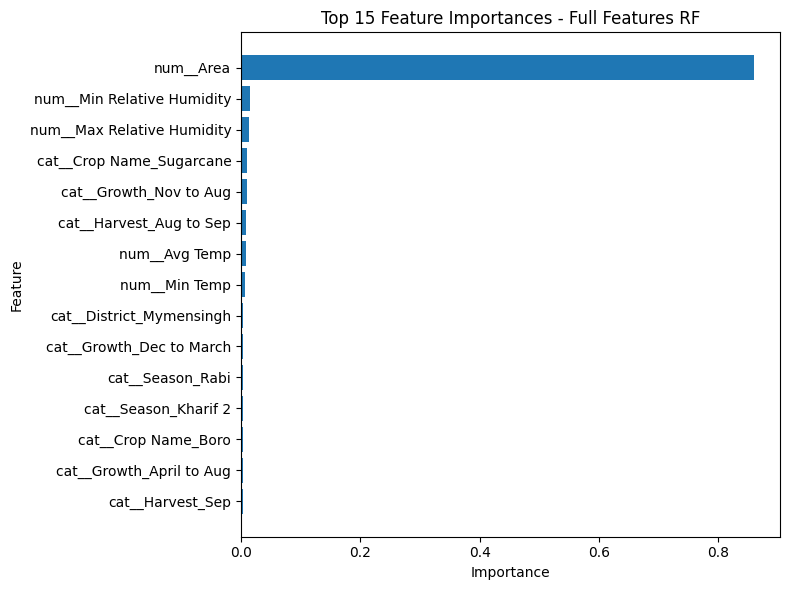


PERMUTATION IMPORTANCE
              Feature  Importance Mean  Importance SD
                 Area         2.385479       0.129076
Min Relative Humidity         0.073325       0.018515
             Min Temp         0.026878       0.005597
            Crop Name         0.015683       0.002000
Max Relative Humidity         0.013000       0.004154
               Growth         0.007489       0.002061
              Harvest         0.006644       0.002500
             Avg Temp         0.005815       0.004274
               Season         0.004020       0.002214
         Avg Humidity         0.002370       0.000757
           Transplant         0.001781       0.001265
             Max Temp         0.000373       0.000854
             District        -0.000714       0.001452


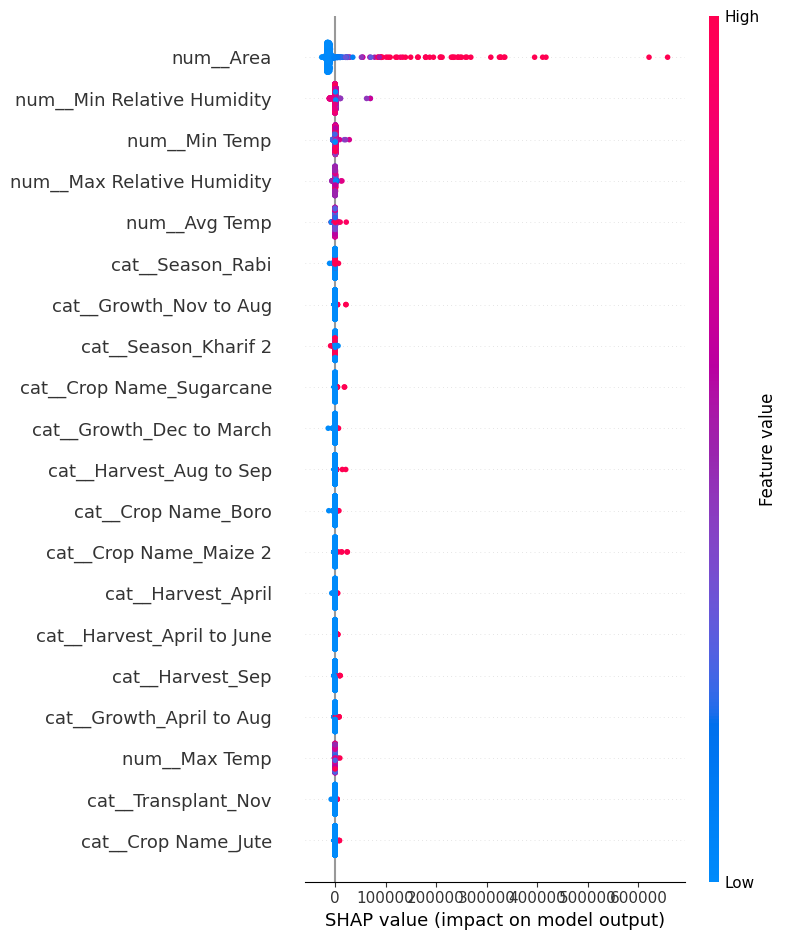


TOP 20 WITHOUT AREA RF IMPORTANCE
                 Feature  Importance
     cat__Crop Name_Boro    0.310348
     cat__Crop Name_Jute    0.054310
    cat__District_Natore    0.053520
 cat__Harvest_Nov to Dec    0.045367
cat__District_Mymensingh    0.044756
     cat__Crop Name_Aman    0.042304
cat__Growth_July to  Oct    0.038085
  cat__District_Faridpur    0.033267
   cat__District_Naogaon    0.023361
     cat__District_Pabna    0.022537
    cat__District_Bogura    0.018399
 cat__District_Sunamganj    0.017217
   cat__District_Jashore    0.016908
 cat__District_Chuadanga    0.015505
   cat__District_Tangail    0.014798
 cat__District_Netrokona    0.013861
   cat__District_Rangpur    0.013274
   cat__District_Kushtia    0.011541
  cat__District_Dinajpur    0.011349
   cat__District_Cumilla    0.011315


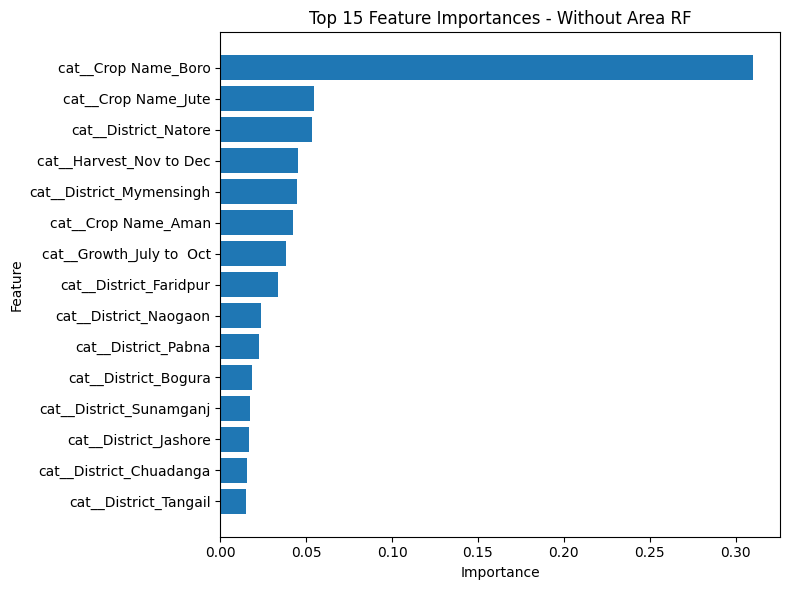

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# -------------------------
# Clean dataset assumed:
# df_clean = 4191 rows
# AP Ratio already removed
# -------------------------

target = "Production"

area_features = ["Area"]

agroclimatic_features = [
    "Avg Temp",
    "Avg Humidity",
    "Max Temp",
    "Min Temp",
    "Max Relative Humidity",
    "Min Relative Humidity"
]

crop_features = ["Crop Name"]
geographic_features = ["District"]

lifecycle_features = [
    "Season",
    "Transplant",
    "Growth",
    "Harvest"
]

full_features = (
    area_features
    + agroclimatic_features
    + crop_features
    + geographic_features
    + lifecycle_features
)

without_area_features = (
    agroclimatic_features
    + crop_features
    + geographic_features
    + lifecycle_features
)

# =====================================================
# 1. Full Features Random Forest
# =====================================================

X = df_clean[full_features]
y = df_clean[target]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

categorical_cols = [
    c for c in full_features
    if df_clean[c].dtype == "object"
]

numerical_cols = [
    c for c in full_features
    if c not in categorical_cols
]

preprocessor = ColumnTransformer([
    (
        "cat",
        OneHotEncoder(handle_unknown="ignore"),
        categorical_cols
    ),
    (
        "num",
        "passthrough",
        numerical_cols
    )
])

rf_full = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

full_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("model", rf_full)
])

full_pipe.fit(X_train, y_train)

pred = full_pipe.predict(X_test)

print("FULL FEATURES RF")
print("R2:", r2_score(y_test, pred))
print("MAE:", mean_absolute_error(y_test, pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred)))

# =====================================================
# 2. Full RF Feature Importance
# =====================================================

feature_names = (
    full_pipe
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

importances = (
    full_pipe
    .named_steps["model"]
    .feature_importances_
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values(
    "Importance",
    ascending=False
)

print("\nTOP 20 FULL FEATURES RF IMPORTANCE")
print(importance_df.head(20).to_string(index=False))

top15 = importance_df.head(15).sort_values(
    "Importance",
    ascending=True
)

plt.figure(figsize=(8, 6))
plt.barh(
    top15["Feature"],
    top15["Importance"]
)
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 15 Feature Importances - Full Features RF")
plt.tight_layout()
plt.show()

# =====================================================
# 3. Permutation Importance on raw predictors
# =====================================================

perm = permutation_importance(
    full_pipe,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="r2",
    n_jobs=-1
)

perm_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance Mean": perm.importances_mean,
    "Importance SD": perm.importances_std
}).sort_values(
    "Importance Mean",
    ascending=False
)

print("\nPERMUTATION IMPORTANCE")
print(perm_df.to_string(index=False))

# =====================================================
# 4. SHAP Analysis
# =====================================================

X_test_transformed = (
    full_pipe
    .named_steps["preprocessor"]
    .transform(X_test)
)

if hasattr(X_test_transformed, "toarray"):
    X_test_transformed = X_test_transformed.toarray()

rf_model = full_pipe.named_steps["model"]

explainer = shap.TreeExplainer(rf_model)

shap_values = explainer.shap_values(
    X_test_transformed,
    check_additivity=False
)

shap.summary_plot(
    shap_values,
    X_test_transformed,
    feature_names=feature_names,
    max_display=20,
    show=True
)

# =====================================================
# 5. WITHOUT AREA RF - retrained correctly
# =====================================================

X_wa = df_clean[without_area_features]
y_wa = df_clean[target]

X_train_wa, X_test_wa, y_train_wa, y_test_wa = train_test_split(
    X_wa,
    y_wa,
    test_size=0.20,
    random_state=42
)

cat_wa = [
    c for c in without_area_features
    if df_clean[c].dtype == "object"
]

num_wa = [
    c for c in without_area_features
    if c not in cat_wa
]

prep_wa = ColumnTransformer([
    (
        "cat",
        OneHotEncoder(handle_unknown="ignore"),
        cat_wa
    ),
    (
        "num",
        "passthrough",
        num_wa
    )
])

rf_wa = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

wa_pipe = Pipeline([
    ("preprocessor", prep_wa),
    ("model", rf_wa)
])

wa_pipe.fit(X_train_wa, y_train_wa)

wa_names = (
    wa_pipe
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

wa_importances = (
    wa_pipe
    .named_steps["model"]
    .feature_importances_
)

wa_imp_df = pd.DataFrame({
    "Feature": wa_names,
    "Importance": wa_importances
}).sort_values(
    "Importance",
    ascending=False
)

print("\nTOP 20 WITHOUT AREA RF IMPORTANCE")
print(wa_imp_df.head(20).to_string(index=False))

top15_wa = wa_imp_df.head(15).sort_values(
    "Importance",
    ascending=True
)

plt.figure(figsize=(8, 6))
plt.barh(
    top15_wa["Feature"],
    top15_wa["Importance"]
)
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 15 Feature Importances - Without Area RF")
plt.tight_layout()
plt.show()

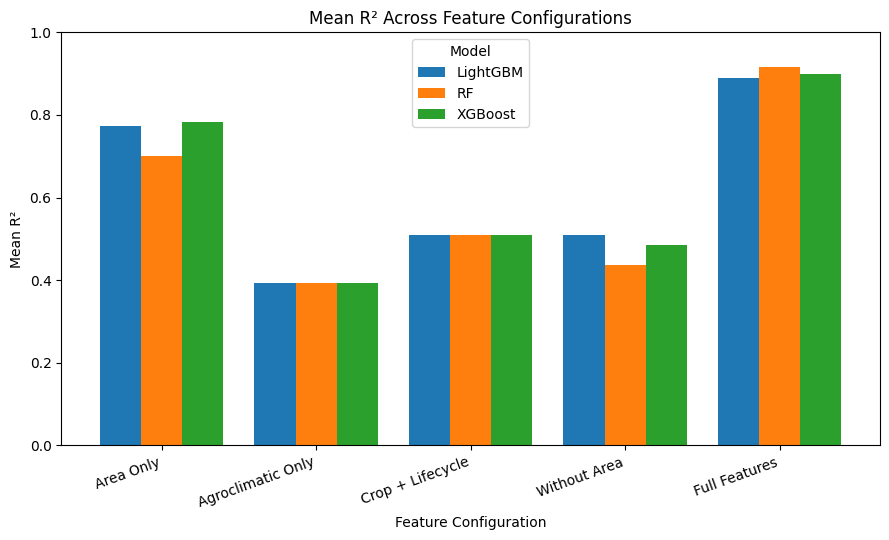

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

# Mean R² values from 5-fold cross-validation
plot_data = pd.DataFrame({
    "Configuration": [
        "Area Only", "Area Only", "Area Only",
        "Agroclimatic Only", "Agroclimatic Only", "Agroclimatic Only",
        "Crop + Lifecycle", "Crop + Lifecycle", "Crop + Lifecycle",
        "Without Area", "Without Area", "Without Area",
        "Full Features", "Full Features", "Full Features"
    ],
    "Model": [
        "RF", "XGBoost", "LightGBM",
        "RF", "XGBoost", "LightGBM",
        "RF", "XGBoost", "LightGBM",
        "RF", "XGBoost", "LightGBM",
        "RF", "XGBoost", "LightGBM"
    ],
    "R2": [
        0.700, 0.782, 0.773,
        0.394, 0.394, 0.394,
        0.509, 0.509, 0.509,
        0.437, 0.486, 0.510,
        0.916, 0.899, 0.889
    ]
})

pivot = plot_data.pivot(
    index="Configuration",
    columns="Model",
    values="R2"
)

# Keep desired order
order = [
    "Area Only",
    "Agroclimatic Only",
    "Crop + Lifecycle",
    "Without Area",
    "Full Features"
]

pivot = pivot.loc[order]

ax = pivot.plot(
    kind="bar",
    figsize=(9, 5.5),
    width=0.8
)

ax.set_xlabel("Feature Configuration")
ax.set_ylabel("Mean R²")
ax.set_title("Mean R² Across Feature Configurations")
ax.set_ylim(0, 1.0)

plt.xticks(rotation=20, ha="right")
plt.legend(title="Model")
plt.tight_layout()

plt.savefig(
    "Fig2_R2_Comparison_5FoldCV.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

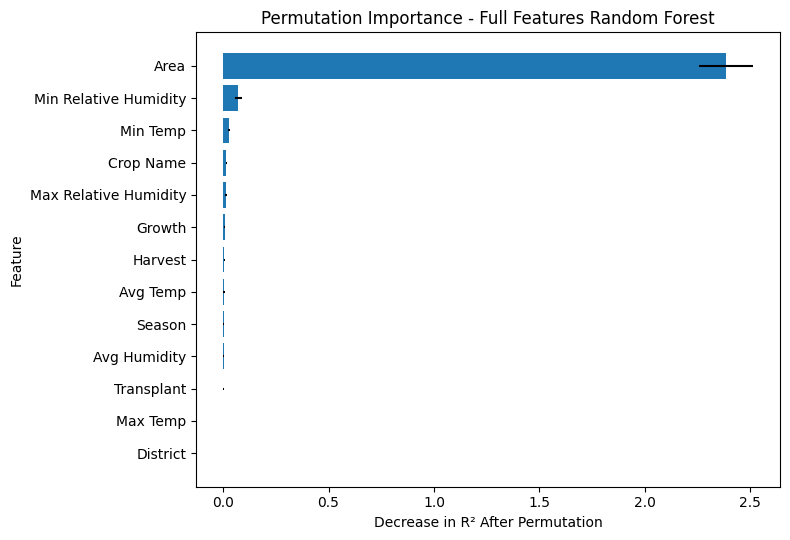

In [13]:
import matplotlib.pyplot as plt

perm_plot = perm_df.sort_values(
    "Importance Mean",
    ascending=True
)

plt.figure(figsize=(8, 5.5))

plt.barh(
    perm_plot["Feature"],
    perm_plot["Importance Mean"],
    xerr=perm_plot["Importance SD"]
)

plt.xlabel("Decrease in R² After Permutation")
plt.ylabel("Feature")
plt.title("Permutation Importance - Full Features Random Forest")

plt.tight_layout()

plt.savefig(
    "Fig4_Permutation_Importance_RF.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()